NAMES:MUGISHA FRANK PATRICK
      LUKOLOLA NGANDA BRUNO

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [74]:
df=pd.read_csv("C:/Users/CARDX LTD/Downloads/ML project/uncleaned_cold_storage_dataset.csv")
display(df.shape)
display(df.head(10))
display(df.info(10))


(200, 5)

,timestamp,temperature_c,humidity_pct,door_status,device_id
0,2026-10-15 00:00:00,4.25,85.54,CLOSED,CS_NODE_01
1,2026-10-15 00:15:00,3.93,85.84,CLOSED,CS_NODE_01
2,2026-10-15 00:30:00,4.32,86.62,CLOSED,CS_NODE_01
3,2026-10-15 00:45:00,4.76,86.58,CLOSED,CS_NODE_01
4,2026-10-15 01:00:00,3.88,82.93,CLOSED,CS_NODE_01
5,2026-10-15 01:15:00,3.88,83.59,CLOSED,CS_NODE_01
6,2026-10-15 01:30:00,4.79,85.77,CLOSED,CS_NODE_01
7,15-10-2026 01:45:00,4.38,85.77,CLOSED,CS_NODE_01
8,2026-10-15 02:00:00,NaN,85.77,CLOSED,CS_NODE_01
9,2026-10-15 02:15:00,4.27,90.78,CLOSED,CS_NODE_01


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   timestamp      200 non-null    str    
 1   temperature_c  195 non-null    float64
 2   humidity_pct   196 non-null    float64
 3   door_status    200 non-null    str    
 4   device_id      200 non-null    str    
dtypes: float64(2), str(3)
memory usage: 14.8 KB


None

In [76]:
display(df.isnull().sum().to_frame("Missing Values"))

,Missing Values
timestamp,0
temperature_c,5
humidity_pct,4
door_status,0
device_id,0


In [77]:
df.duplicated().sum()
df.drop_duplicates()

,timestamp,temperature_c,humidity_pct,door_status,device_id
0,2026-10-15 00:00:00,4.25,85.54,CLOSED,CS_NODE_01
1,2026-10-15 00:15:00,3.93,85.84,CLOSED,CS_NODE_01
2,2026-10-15 00:30:00,4.32,86.62,CLOSED,CS_NODE_01
3,2026-10-15 00:45:00,4.76,86.58,CLOSED,CS_NODE_01
4,2026-10-15 01:00:00,3.88,82.93,CLOSED,CS_NODE_01
...,...,...,...,...,...
195,2026-10-17 00:45:00,4.19,84.30,CLOSED,CS_NODE_02
196,2026-10-17 01:00:00,3.56,82.43,CLOSED,CS_NODE_02
197,2026-10-17 01:15:00,4.08,87.03,CLOSED,CS_NODE_02
198,2026-10-17 01:30:00,4.03,84.83,CLOSED,CS_NODE_02


In [78]:
#Removing extra spaces, putting everything to uppercase
df['door_status'] = (df['door_status'].str.strip().str.upper())

#Fix Timestamp Format 
df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', errors='coerce')
for i in range(1, len(df)):
    if pd.isna(df.loc[i, 'timestamp']):
        df.loc[i, 'timestamp'] = df.loc[i - 1, 'timestamp'] + pd.Timedelta(minutes=15)
# Replace physically impossible sensor glitch values
df.loc[(df['temperature_c'] < -30) | (df['temperature_c'] > 50), 'temperature_c'] = np.nan

#If humidity is below 0 or above 100, replace it with a missing value. 
df.loc[(df['humidity_pct'] < 0) | (df['humidity_pct'] > 100),'humidity_pct'] = np.nan 

#Impute Missing/Outlier Values using Time-Series Linear Interpolation
df['temperature_c'] = df['temperature_c'].interpolate(method='linear')
df['humidity_pct'] = df['humidity_pct'].interpolate(method='linear')

print(f"Cleaned Dataset Shape: {df.shape}")
print("Remaining Missing Values:\n", df.isnull().sum())

Cleaned Dataset Shape: (200, 5)
Remaining Missing Values:
 timestamp        0
temperature_c    0
humidity_pct     0
door_status      0
device_id        0
dtype: int64


In [79]:
print("Data Shape after duplicates", df.shape)
print("Remaining Duplicates", df.duplicated().sum())

Data Shape after duplicates (200, 5)
Remaining Duplicates 0


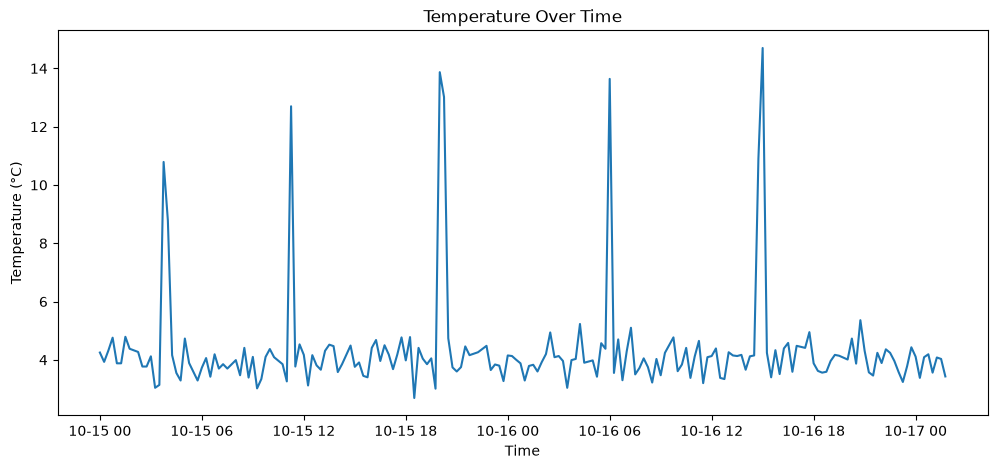

In [80]:
plt.figure(figsize=(12,5))

plt.title('Temperature Over Time')
plt.plot(df['timestamp'], df['temperature_c'])
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')

plt.show()

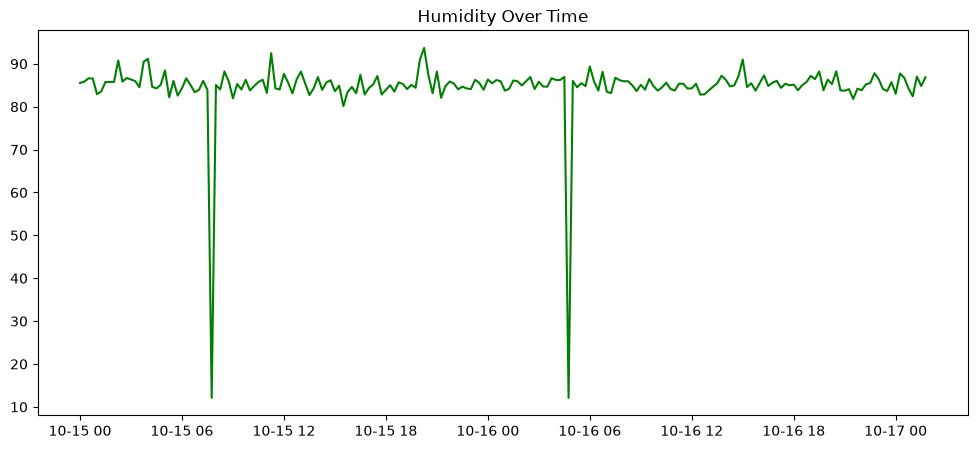

In [81]:
plt.figure(figsize=(12,5))

plt.title('Humidity Over Time')
plt.plot(df['timestamp'], df['humidity_pct'], color='green')
plt.show()

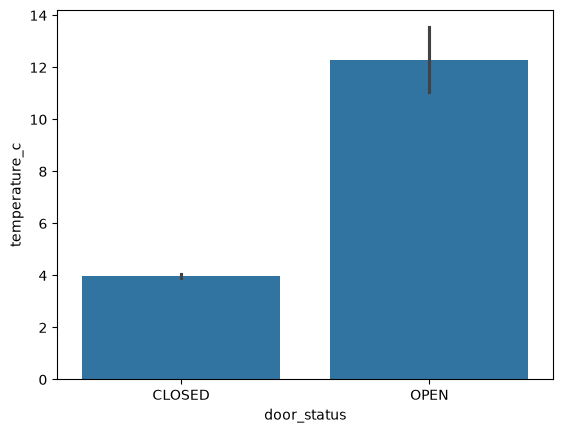

In [82]:
#Door status affect the Temperature
sns.barplot(data=df, x='door_status', y='temperature_c')

plt.show()

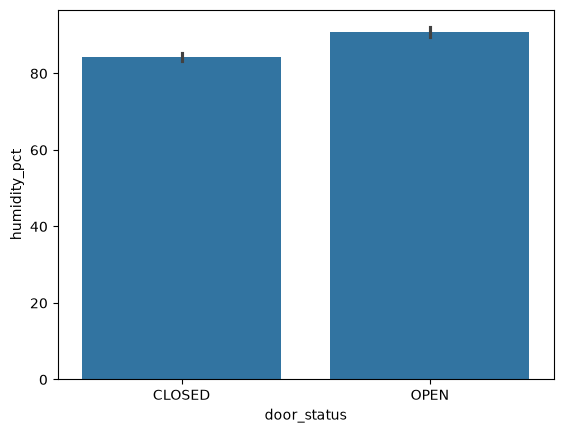

In [83]:
sns.barplot(data=df, x='door_status', y='humidity_pct')

plt.show()

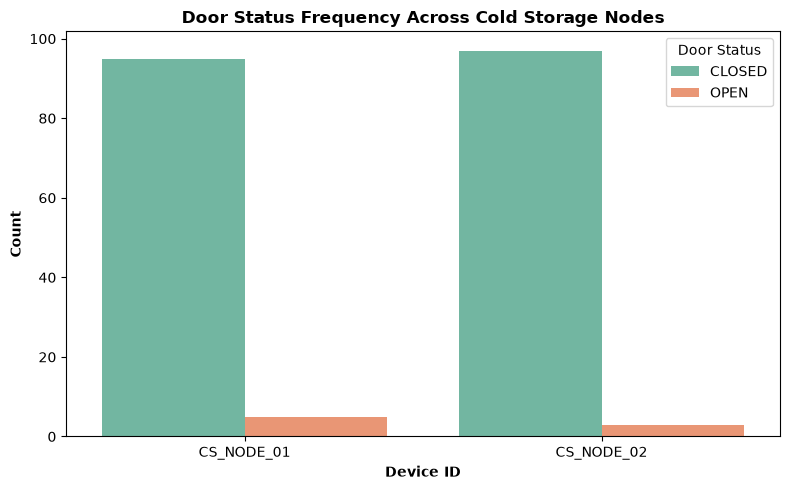

In [84]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='device_id', hue='door_status', palette='Set2')
plt.title('Door Status Frequency Across Cold Storage Nodes', fontsize=12, fontweight='bold')
plt.xlabel('Device ID', fontsize=10, fontweight='bold')
plt.ylabel('Count', fontsize=10, fontweight='bold')
plt.legend(title='Door Status')
plt.tight_layout()
plt.savefig('door_status_distribution.png', dpi=300)
plt.show()

In [87]:
import pickle 
df.to_csv("cleaned_cold_storage_dataset.csv", index=False)
 
print("CSV file saved successfully!")

CSV file saved successfully!


In [86]:
import os
print(os.getcwd())


C:\Users\CARDX LTD
